# Results walkthrough

This notebook reads the committed result files and walks through what they show, one
research sub-question at a time. It computes nothing new: every number here also comes
out of a script in `src/`, and the paper quotes them through `figures/tables/numbers.tex`.
Its purpose is to let a reader (or a grader) inspect the data behind each claim.

Run it from the repository root or from `notebooks/`, after `pip install -r requirements.txt`
and `pip install notebook==7.2.2`.

In [1]:
from pathlib import Path
import json
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
RESULTS = ROOT / "data" / "results"
sys.path.insert(0, str(ROOT / "src"))
pd.set_option("display.width", 120)

tree = pd.read_csv(ROOT / "data" / "hf_tree.csv")
gas = pd.read_csv(RESULTS / "gas.csv")
verify = pd.read_csv(RESULTS / "verify_gas.csv")
guarantees = pd.read_csv(RESULTS / "guarantees.csv")
stats = json.loads((RESULTS / "tree_stats.json").read_text())
model = json.loads((RESULTS / "gas_model.json").read_text())
meta = json.loads((ROOT / "data" / "hf_tree_meta.json").read_text())
print(f"Tree of {meta['base_model']}, pulled {meta['pulled_at_utc'][:10]}: {len(tree)} models")

Tree of HuggingFaceTB/SmolLM2-360M, pulled 2026-10-20: 1369 models


## 1. The data: a real model family tree

Each row of `data/hf_tree.csv` is one model on the Hugging Face Hub that declares
`HuggingFaceTB/SmolLM2-360M` as an ancestor. `parent_id` and `relation` come from the
model card's `base_model` field; `weights_hash` is our hash of the model's weight files
(the value a registry would anchor on-chain); `status` says whether the model can be
registered at all.

In [2]:
tree[["model_id", "parent_id", "relation", "depth", "weights_hash", "status"]].head()

,model_id,parent_id,relation,depth,weights_hash,status
0,HuggingFaceTB/SmolLM2-360M,NaN,base,0,0x32a7c7e06007965a35c158d0877ae906b917d69a7a73...,ok
1,2nji/sft_numina-cot_SmolLM2-360M,HuggingFaceTB/SmolLM2-360M,finetune,1,0x9e5ee278ade9ce1e5f37a89a04ca67e59164203783c2...,ok
2,AZH04/SmolLM2-360M-base-gsm8k-boxed-sft,HuggingFaceTB/SmolLM2-360M,finetune,1,0x6c40967f4bc85eebb0f483e3e2da259c393366d6498d...,ok
3,AZH04/SmolLM2-360M-base-gsm8k-boxed-sft-ep12,HuggingFaceTB/SmolLM2-360M,finetune,1,0xa4b71773be935287ac3e98c68e91eeab56c6237b915f...,ok
4,AZH04/SmolLM2-360M-base-gsm8k-boxed-sft-ep16,HuggingFaceTB/SmolLM2-360M,finetune,1,0xab8e978e9a894e6ff8c67094d075f891a220b6e7214f...,ok


In [3]:
pd.crosstab(tree["depth"], tree["relation"], margins=True)

relation,adapter,base,finetune,merge,quantized,All
depth,,,,,,
0,0,1,0,0,0,1
1,19,0,130,1,43,193
2,275,0,209,1,154,639
3,193,0,78,3,107,381
4,23,0,97,0,35,155
All,510,1,514,5,339,1369


### How 1,369 models become 1,071 registrable ones

A model is excluded if it has no weight files, declares more than one parent (our three
designs record one parent per model), duplicates another model's weights, or sits below an
excluded ancestor. The last reason is by far the largest, and almost all of it traces back
to a single model:

In [4]:
excluded = pd.Series(stats["excluded_by_reason"]).rename("models")
print(excluded.to_string(), f"\ntotal excluded: {excluded.sum()}, registrable: {stats['n_registrable']}")
pd.DataFrame(stats["ancestor_not_registered_root_causes"]["top_blocking_models"]).head(5)

ancestor_not_registered    223
multi_parent                34
duplicate_weights           25
no_weight_files             16 
total excluded: 298, registrable: 1071


,model_id,reason,descendants_blocked
0,HuggingFaceTB/SmolVLM-500M-Instruct,multi_parent,215
1,Fu01978/SmolMoE-4x360M-Instruct,multi_parent,2
2,GoofyLM/BrainrotLM2-Assistant-362M,multi_parent,2
3,zeustek/Wayo_GPT,multi_parent,1
4,jekunz/smollm360m-da05-is1-nno05-nob05-sv05-ties,multi_parent,1


## 2. Registration cost per design

`gas.csv` has one row per (design, batch size, model). For storage and event-only every
model is its own transaction, so `gas_per_model` equals `tx_gas`. For Merkle, one
transaction anchors a whole batch of k models: only the first row of a batch carries
`tx_gas`, and `gas_per_model` is that cost divided by the batch's size.

In [5]:
summary = (gas.groupby(["design", "batch_size"])["gas_per_model"]
             .agg(["mean", "min", "max", "count"]).round(0).astype(int))
summary

mean     min     max  count
design  batch_size                               
event   1            33360   32468   50138   1071
merkle  1            75639   75589   92701   1071
        8             9477    9449   11588   1071
        32            2416    2362    5041   1071
        128            651     590    1608   1071
storage 1           219771  190874  259650   1071

### Why storage costs what it does

The storage design writes the record into contract storage, and a new 32-byte storage slot
costs 22,100 gas (EIP-2929 cold access plus EIP-2200 zero-to-nonzero write). The URI is a
string, so every extra 32 bytes of URI needs one more slot. `src/gas_model.py` fits a
least-squares line to this; the fitted price per URI word lands right next to the EVM's
slot price, which is the evidence that we understand where the gas goes.

In [6]:
storage = gas[gas["design"] == "storage"].copy()
storage["uri_words"] = np.ceil(storage["uri_bytes"] / 32).astype(int)
print(storage.groupby("uri_words")["gas_per_model"].agg(["mean", "count"]).round(0))
fit = model["storage"]
print(f"\nfit: +{fit['coefficients']['uri_words']:,.0f} gas per URI word "
      f"(EVM new slot: {model['evm_reference']['new_storage_slot']:,}), "
      f"R^2 = {fit['r_squared']:.4f}, largest residual {fit['max_abs_residual']:.0f} gas")

               mean  count
uri_words                 
2          191799.0     24
3          217634.0    922
4          240601.0    123
5          259602.0      2

fit: +22,842 gas per URI word (EVM new slot: 22,100), R^2 = 0.9999, largest residual 253 gas


### When Merkle batching beats event logs

A Merkle batch costs about the same whatever k is (one root is stored), so the cost per
model falls roughly as 1/k. The event design costs a fixed amount per model. The two lines
cross between k = 2 and k = 3:

cheaper than events from k = 3


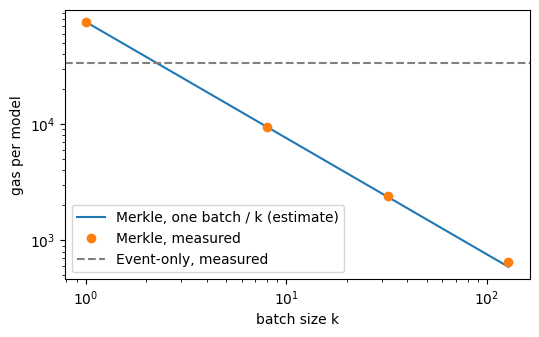

In [7]:
single = model["merkle"]["by_batch_size"]["1"]["mean_full_batch_gas"]
event_mean = gas.loc[gas["design"] == "event", "gas_per_model"].mean()
k = np.arange(1, 129)
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.loglog(k, single / k, label="Merkle, one batch / k (estimate)")
measured = summary.loc["merkle", "mean"]
ax.loglog(measured.index, measured.values, "o", label="Merkle, measured")
ax.axhline(event_mean, color="grey", ls="--", label="Event-only, measured")
ax.set_xlabel("batch size k"); ax.set_ylabel("gas per model"); ax.legend()
print("cheaper than events from k =", model["merkle"]["cheaper_than_event_from_k"])

## 3. Verification cost

Cheap registration is only half of the question: a contract that wants to trust a model
(for example, before paying a royalty) must verify its record. `verify_gas.csv` measures
this inside a contract (`VerifyProbe.sol`) for one record and for the whole lineage back
to the base model. Event logs cannot be read by a contract at all.

In [8]:
(verify.groupby(["design", "batch_size", "lineage_len"])["lineage_gas"].mean()
       .unstack("lineage_len").round(0))

lineage_len               1        2        3        4        5
design  batch_size                                             
merkle  1            9121.0  18245.0  27366.0  36482.0  45605.0
        8           10100.0  20207.0  30307.0  40406.0  50510.0
        32          10757.0  21521.0  32274.0  42985.0  53472.0
        128         11405.0  22823.0  34230.0  45544.0  56328.0
storage 1            8885.0  11694.0  14503.0  17312.0  20121.0

Storage verification grows slowly with depth (one storage read per generation), while
each Merkle generation needs its own proof, about 11,000 gas at k = 128. So the cheapest
design to register in is the most expensive to verify: the trade-off the paper reports.

## 4. What each design guarantees

`src/audit_checks.py` runs seven checks against every design on Anvil and records the
evidence. `test/test_audit_checks.py` fails if a contract change alters this table.

In [9]:
guarantees.pivot(index="check", columns="design", values="result")

design,event,merkle,storage
check,,,
A model's lineage can be followed on-chain,off-chain only,with proof,yes
A record whose parent was never registered is refused,yes,no,yes
A tampered weights hash is detected,off-chain only,with proof,yes
An empty (zero) weights hash is refused,yes,no,yes
Another contract can check a record,no,with proof,yes
Registering the same weights twice is refused,no,no,yes
The owner of one model can hand it to another account,no,no,yes


## 5. Where every number in the paper comes from

The paper quotes numbers through `\\result{key}` macros generated by `src/make_numbers.py`.
This is the full list, recomputed here from the same files:

In [10]:
from make_numbers import collect
numbers = pd.Series(collect(ROOT / "data", RESULTS)).str.replace("{,}", ",", regex=False)
numbers.to_frame("value")

,value
tree.base,\texttt{HuggingFaceTB/SmolLM2-360M}
tree.pulled,2026-10-20
tree.models,"1,369"
tree.maxdepth,4
tree.registrable,"1,071"
tree.registrable.pct,78.2\%
tree.weightshash.pct,98.8\%
tree.datasets.pct,19.8\%
tree.children.mean,15.2
tree.excluded,298
